# Cramér's V among the variables that have values for children under 2

**What this notebook does.** Using the revised MICS child file (`MICS-child-ISRC-revised.dta`), it keeps only **children aged under 2** (completed years 0 and 1) and computes **Cramér's V** between every pair of categorical variables that have values for those children, plus each variable's association with `severe_wasting`.

## Cramér's V in plain words
* It measures **how strongly two category-type columns are linked**, on a scale from **0** (unrelated) to **1** (knowing one column tells you the other exactly).
* It has **no direction** (it does not say *more* or *less*), it is **symmetric** (V(A, B) = V(B, A)) and it only needs counts, so it works for unordered categories such as `division` or `water_cat`.
* **Formula.** `V = sqrt( chi2 / (n * min(r - 1, c - 1)) )`, where `chi2` is the chi-square statistic of the r x c table of counts and `n` is the number of children with both values.
* **Bias-corrected V** (Bergsma 2013, called `V_corr` below) removes the upward bias that small samples and many categories cause. **It is the number to read.** The classic V is also reported.
* **Weighted V** uses the survey weight `chweight` (rescaled to sum to the pair's sample size); it is descriptive only.

| Smaller table side `min(r-1, c-1)` | small | medium | large |
|---|---|---|---|
| 1 (for example binary x anything) | 0.10 | 0.30 | 0.50 |
| 2 | 0.07 | 0.21 | 0.35 |
| 3 | 0.06 | 0.17 | 0.29 |
| 4 or more | 0.05 | 0.15 | 0.25 |

(Cohen's rule-of-thumb sizes. With only about 3% of under-2 children severely wasted, even a real risk factor produces a **small V** with the outcome, so use the confidence intervals and the ranking rather than the absolute size.)

## Important reading rules
* **Not design-based.** The chi-square p-values treat children as independent and unweighted; MICS is clustered and weighted. They are used only for screening. For the association with `severe_wasting` a **PSU cluster bootstrap** gives the confidence intervals and Benjamini-Hochberg FDR controls the many tests.
* **Structural pairs.** Some variables are built from each other (`dds` is the sum of the `fg_*` indicators; `small_at_birth` comes from `birth_size`; and so on). These pairs have a high V *by construction*; they are flagged, not interpreted as findings.
* **Variables with continuous values** are binned (rules are printed in the inventory), and rare levels of ordered variables are merged so tables are not mostly empty cells.

## Sections
1. Setup and configuration  2. Data loading (age < 2)  3. Variable inventory and recoding  4. Cramér's V functions with tests  5. All pairs  6. Association with `severe_wasting` (bootstrap CI, FDR)  7. Heatmaps and top pairs  8. Findings, files and limitations

In [1]:
# ===== 1. Setup and configuration =====
import warnings, os, sys, time, json, hashlib, platform
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats.contingency import association
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform

PROFILES = {'smoke': dict(psu_frac=0.3, n_boot=30),        # code test on a PSU subsample only; never report
            'standard': dict(psu_frac=1.0, n_boot=1000)}
PROFILE = os.environ.get('CRAMER_PROFILE', 'standard')
if PROFILE not in PROFILES: raise ValueError(f'CRAMER_PROFILE must be one of {list(PROFILES)}')
PSU_FRAC, N_BOOT = PROFILES[PROFILE]['psu_frac'], PROFILES[PROFILE]['n_boot']
BOOT_SEED = 20261027

MIN_COVERAGE = 0.20            # a variable needs a value for at least 20% of the under-2 children
MIN_PAIR_N = 300               # pairs with fewer complete children are flagged
MIN_LEVEL_N = 50               # rare levels of ORDERED variables are merged until each has at least this many children
MAX_RAW_LEVELS = 8             # numeric variables with more distinct values are binned
N_QUANTILE_BINS = 4
INFANT_SPECIFIC_MAX_COV_2_4 = 0.05   # "infant-specific" = at most 5% of children aged 2-4 have a value

DATA_FILE = 'MICS-child-ISRC-revised.dta'
SEARCH_DIRS = ['.', '..', 'data', '/mnt/user-data/uploads', '/mnt/user-data/outputs']
OUT, FIG = 'outputs_cramers_v', 'figures_cramers_v'
for d_ in (OUT, FIG): os.makedirs(d_, exist_ok=True)
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})
T0 = time.time()
print(f'Profile={PROFILE} | bootstrap replicates={N_BOOT} | min coverage={MIN_COVERAGE:.0%} | min pair n={MIN_PAIR_N}')

Profile=standard | bootstrap replicates=1000 | min coverage=20% | min pair n=300


## 2. Data loading: children aged under 2 only

`ub2` is age in completed years, so "under 2" means `ub2` is 0 or 1 (this equals the file's `young` flag, which the notebook asserts). Children aged 2-4 are used only to tell which variables are *infant-specific* (blank for them).

In [2]:
# ===== 2. Load the revised file and keep children aged < 2 =====
def find_file(name):
    for d_ in SEARCH_DIRS:
        p_ = os.path.join(d_, name)
        if os.path.exists(p_): return p_
    return None
path = find_file(DATA_FILE)
if path is None: raise FileNotFoundError(f'{DATA_FILE} not found. Searched: {SEARCH_DIRS}')
data = pd.read_stata(path, convert_categoricals=False)
with pd.io.stata.StataReader(path) as _r: LABELS = _r.variable_labels()

need = ['ub2', 'young', 'severe_wasting', 'hh1', 'chweight', 'child_id']
miss = [c for c in need if c not in data.columns]
if miss: raise KeyError(f'Missing required columns: {miss}')
assert data.shape[1] == 80, f'Expected the revised file with 80 columns, found {data.shape[1]}. Is this the revised file?'
data = data[data['chweight'] > 0].reset_index(drop=True)
assert ((data['ub2'] < 2).astype(int) == data['young']).all(), '`young` must equal (age in whole years < 2)'

if PSU_FRAC < 1.0:
    keep_ = pd.Series(data['hh1'].unique()).sample(frac=PSU_FRAC, random_state=0)
    data = data[data['hh1'].isin(set(keep_))].reset_index(drop=True); print('SMOKE TEST subsample - results are not reportable')
u2 = data[data['ub2'] < 2].reset_index(drop=True)          # children aged under 2
older = data[data['ub2'] >= 2]                              # used only for the "infant-specific" classification
N = len(u2); Y = u2['severe_wasting'].to_numpy(int); W = u2['chweight'].to_numpy(float); PSU = u2['hh1'].to_numpy()
print(f'Children aged < 2: {N:,} | severely wasted: {Y.sum()} ({Y.mean()*100:.2f}% unweighted, {np.average(Y, weights=W)*100:.2f}% weighted) | PSUs: {len(np.unique(PSU))}')

Children aged < 2: 8,888 | severely wasted: 297 (3.34% unweighted, 3.32% weighted) | PSUs: 2930


## 3. Variable inventory and recoding

For every column the notebook records how many under-2 children have a value, whether it is **infant-specific** (blank for children aged 2-4) or general, and decides whether it enters the analysis.

* **Never included:** identifiers and design fields, the 67-level district `hh7a` (too many levels), and `whz2`, `mod_wasting`, `any_wasting`, `wast_cat` (derived from the same WHZ measurement as the outcome, so their V with the outcome would be meaningless). `wb4` and `cm11` are left out because their categorised versions `mage_cat` and `parity_cat` are already included. `young` is constant here.
* **Included only if** at least 20% of under-2 children have a value and the variable has at least two levels.
* **Recoding:** age in months and birth weight use fixed bands; any other numeric variable with more than 8 distinct values is cut into quartiles; ordered variables with rare levels have the smallest level merged into its smaller neighbour until every level has at least 50 children. Unordered variables keep their raw levels (sparse ones are flagged).

In [3]:
# ===== 3. Inventory, inclusion rules, recoding =====
EXCLUDE = {'hh1': 'design (PSU)', 'hh2': 'identifier', 'ln': 'identifier', 'child_id': 'identifier', 'mother_id': 'identifier', 'hh_id': 'identifier',
           'strata': 'design (stratum)', 'chweight': 'design (weight)', 'hh7a': 'district: 67 levels (use division)',
           'whz2': 'outcome-derived (continuous WHZ)', 'mod_wasting': 'outcome-derived', 'any_wasting': 'outcome-derived', 'wast_cat': 'outcome-derived',
           'young': 'constant for children under 2', 'wb4': 'continuous; categorised version mage_cat is included', 'cm11': 'continuous; categorised version parity_cat is included'}
TARGET = 'severe_wasting'
ORDERED = {'wealth', 'edu_level', 'dds', 'bd9', 'n_under5', 'birth_order', 'birth_interval', 'mother_age_at_birth', 'parity_cat', 'mage_cat', 'diarr_sev', 'birth_size'}
BANDS = {'age_m': ([0, 6, 12, 18, 24], ['0-5m', '6-11m', '12-17m', '18-23m']),
         'birth_wt': ([0, 2.5, 3.0, 3.5, 99], ['<2.5kg', '2.5-2.99kg', '3.0-3.49kg', '>=3.5kg'])}

def merge_rare_ordered(s, min_n):
    vals = sorted(s.dropna().unique()); cnt = [float((s == v).sum()) for v in vals]; groups = [[v] for v in vals]
    while len(groups) > 2 and min(cnt) < min_n:
        i = int(np.argmin(cnt))
        j = 1 if i == 0 else (i - 1 if i == len(cnt) - 1 else (i - 1 if cnt[i - 1] <= cnt[i + 1] else i + 1))
        lo, hi = min(i, j), max(i, j); groups[lo] += groups[hi]; cnt[lo] += cnt[hi]; del groups[hi], cnt[hi]
    mapping = {v: gi for gi, g in enumerate(groups) for v in g}
    labels = [f'{g[0]:g}' if len(g) == 1 else f'{g[0]:g}-{g[-1]:g}' for g in groups]
    return s.map(mapping), labels

def recode(name, s):
    # returns (integer codes with -1 for missing, level labels, description of the recoding)
    if name in BANDS:
        edges, labs = BANDS[name]; c = pd.cut(s, edges, right=False, labels=labs); return c.cat.codes.to_numpy(int), list(labs), f'fixed bands {labs}'
    nun = s.nunique()
    if nun > MAX_RAW_LEVELS:
        c = pd.qcut(s, N_QUANTILE_BINS, duplicates='drop'); return c.cat.codes.to_numpy(int), [str(x) for x in c.cat.categories], f'{N_QUANTILE_BINS} quantile bins'
    if name in ORDERED:
        m, labs = merge_rare_ordered(s, MIN_LEVEL_N); codes = m.fillna(-1).to_numpy(int)
        raw = sorted(s.dropna().unique())
        return codes, labs, ('raw levels' if len(labs) == len(raw) else f'rare ordered levels merged ({len(raw)} -> {len(labs)})')
    c = pd.Categorical(s); return c.codes.astype(int), [f'{x:g}' for x in c.categories], 'raw levels'

inv_rows, CODES, LEVELS = [], {}, {}
for col in data.columns:
    s_all = u2[col]; cov = s_all.notna().mean(); cov_old = older[col].notna().mean() if len(older) else np.nan
    row = {'variable': col, 'label': str(LABELS.get(col, ''))[:60], 'n_valid_under2': int(s_all.notna().sum()), 'coverage_under2_%': round(100 * cov, 1),
           'coverage_age2_4_%': round(100 * cov_old, 1),
           'availability': 'infant-specific' if cov_old <= INFANT_SPECIFIC_MAX_COV_2_4 else 'general (also ages 2-4)'}
    if col == TARGET: row.update(included=False, reason='target (analysed separately in section 6)')
    elif col in EXCLUDE: row.update(included=False, reason=EXCLUDE[col])
    elif cov < MIN_COVERAGE: row.update(included=False, reason=f'coverage {100*cov:.0f}% < {100*MIN_COVERAGE:.0f}%')
    elif s_all.nunique() < 2: row.update(included=False, reason='fewer than 2 levels')
    else:
        codes, labs, how = recode(col, s_all.astype(float)); CODES[col], LEVELS[col] = codes, labs
        counts = np.bincount(codes[codes >= 0], minlength=len(labs))
        row.update(included=True, reason='', recoding=how, n_levels_raw=int(s_all.nunique()), n_levels_final=len(labs), levels='; '.join(labs),
                   smallest_level_n=int(counts.min()), sparse_level_flag=bool(counts.min() < 30))
    inv_rows.append(row)
inventory = pd.DataFrame(inv_rows); inventory.to_csv(f'{OUT}/variable_inventory.csv', index=False)
VARS = [v for v in inventory.loc[inventory.included, 'variable']]
AVAIL = inventory.set_index('variable')['availability'].to_dict()
CODES[TARGET] = Y.copy(); LEVELS[TARGET] = ['0', '1']

print(f'{len(VARS)} variables included ({sum(AVAIL[v] == "infant-specific" for v in VARS)} infant-specific, {sum(AVAIL[v] != "infant-specific" for v in VARS)} general).')
with pd.option_context('display.width', 230, 'display.max_colwidth', 70, 'display.max_rows', 200):
    print('\nIncluded variables:')
    print(inventory[inventory.included][['variable', 'availability', 'coverage_under2_%', 'coverage_age2_4_%', 'n_levels_final', 'recoding', 'smallest_level_n']].to_string(index=False))
    print('\nNot included:')
    print(inventory[~inventory.included][['variable', 'coverage_under2_%', 'reason']].to_string(index=False))

63 variables included (23 infant-specific, 40 general).

Included variables:
            variable            availability  coverage_under2_%  coverage_age2_4_%  n_levels_final                                                      recoding  smallest_level_n
                 ub2 general (also ages 2-4)              100.0              100.0             2.0                                                    raw levels            4239.0
               age_m general (also ages 2-4)              100.0              100.0             4.0             fixed bands ['0-5m', '6-11m', '12-17m', '18-23m']            2071.0
              female general (also ages 2-4)              100.0              100.0             2.0                                                    raw levels            4316.0
            division general (also ages 2-4)              100.0              100.0             8.0                                                    raw levels             515.0
               urban general

## 4. Cramér's V functions (tested)

Counts are built from integer codes (missing = -1) using only children with a value for **both** variables ("pairwise complete"). Empty levels are dropped. The code is checked before use: classic V, chi-square and p-values against `scipy`, the bias-corrected V against an independent implementation of Bergsma's formula, and by a simulation showing that the correction removes the small-sample bias under independence.

In [4]:
# ===== 4. Cramer's V =====
def contingency(a, b, w=None):
    m = (a >= 0) & (b >= 0); a2, b2 = a[m], b[m]
    if len(a2) == 0: return np.zeros((0, 0))
    ua, ub = np.unique(a2), np.unique(b2); ia, ib = np.searchsorted(ua, a2), np.searchsorted(ub, b2)
    return np.bincount(ia * len(ub) + ib, weights=None if w is None else w[m], minlength=len(ua) * len(ub)).reshape(len(ua), len(ub))

def v_stats(t):
    nan = dict(n=float(t.sum()), r=t.shape[0], c=t.shape[1], chi2=np.nan, dof=np.nan, p=np.nan, V=np.nan, V_corr=np.nan, min_expected=np.nan, pct_cells_expected_lt5=np.nan)
    r, c = t.shape; n = t.sum()
    if r < 2 or c < 2 or n <= 1: return nan
    E = t.sum(1, keepdims=True) @ t.sum(0, keepdims=True) / n
    chi2 = float(((t - E) ** 2 / E).sum()); k = min(r - 1, c - 1); phi2 = chi2 / n
    phi2c = max(0.0, phi2 - (r - 1) * (c - 1) / (n - 1)); rc = r - (r - 1) ** 2 / (n - 1); cc = c - (c - 1) ** 2 / (n - 1)
    return dict(n=float(n), r=r, c=c, chi2=chi2, dof=(r - 1) * (c - 1), p=float(stats.chi2.sf(chi2, (r - 1) * (c - 1))), V=float(np.sqrt(phi2 / k)),
                V_corr=float(np.sqrt(phi2c / max(min(rc - 1, cc - 1), 1e-12))), min_expected=float(E.min()), pct_cells_expected_lt5=float(100 * (E < 5).mean()))

def v_weighted(a, b, w):
    m = (a >= 0) & (b >= 0)
    if m.sum() < 2: return np.nan
    ww = w * (m.sum() / w[m].sum()); return v_stats(contingency(a, b, ww))['V_corr']

def v_corr_mult(a, b, mult):
    # bias-corrected V when each child counts `mult` times (PSU bootstrap)
    return v_stats(contingency(a, b, mult))['V_corr']

def size_label(v, k):
    if not np.isfinite(v): return ''
    th = {1: (0.10, 0.30, 0.50), 2: (0.07, 0.21, 0.35), 3: (0.06, 0.17, 0.29)}.get(k, (0.05, 0.15, 0.25))
    return 'large' if v >= th[2] else 'medium' if v >= th[1] else 'small' if v >= th[0] else 'negligible'

# ---- unit tests ----
rs = np.random.RandomState(1)
def bergsma_reference(t):
    # independent re-implementation of the Bergsma (2013) bias-corrected V using scipy's chi-square
    chi2, _, _, _ = stats.chi2_contingency(t, correction=False); n = t.sum(); r, c = t.shape
    phi2 = max(0.0, chi2 / n - (r - 1) * (c - 1) / (n - 1)); rt = r - (r - 1) ** 2 / (n - 1); ct = c - (c - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / (min(rt, ct) - 1))
for _ in range(200):
    r_, c_ = rs.randint(2, 6), rs.randint(2, 6); t_ = rs.randint(5, 80, size=(r_, c_)).astype(float); st = v_stats(t_)
    assert abs(st['V'] - association(t_.astype(int), method='cramer', correction=False)) < 1e-9, 'classic V differs from scipy'
    assert abs(st['chi2'] - stats.chi2_contingency(t_, correction=False)[0]) < 1e-8, 'chi-square differs from scipy'
    assert abs(st['p'] - stats.chi2_contingency(t_, correction=False)[1]) < 1e-10, 'p-value differs from scipy'
    assert abs(st['V_corr'] - bergsma_reference(t_)) < 1e-9, 'bias-corrected V differs from the reference formula'
a_ = rs.randint(0, 3, 400); b_ = (a_ + rs.randint(0, 2, 400)) % 3; assert 0 <= v_stats(contingency(a_, b_))['V'] <= 1
assert abs(v_stats(contingency(a_, a_))['V'] - 1) < 1e-9, 'V of a variable with itself must be 1'
assert v_stats(np.array([[50., 50.], [50., 50.]]))['V'] == 0
# simulation: under independence the classic V is biased upwards in small samples; the corrected V removes most of that bias
sim_c, sim_k = [], []
for _ in range(400):
    x_, y_ = rs.randint(0, 5, 100), rs.randint(0, 5, 100); st = v_stats(contingency(x_, y_)); sim_c.append(st['V']); sim_k.append(st['V_corr'])
assert np.mean(sim_c) > 0.15 and np.mean(sim_k) < 0.06, (np.mean(sim_c), np.mean(sim_k))
print(f'Cramer\'s V verified: classic V, chi-square and p-value match scipy on 200 random tables; V_corr matches an independent Bergsma implementation; '
      f'under independence (5x5, n=100) mean classic V = {np.mean(sim_c):.3f} but mean corrected V = {np.mean(sim_k):.3f}.')

Cramer's V verified: classic V, chi-square and p-value match scipy on 200 random tables; V_corr matches an independent Bergsma implementation; under independence (5x5, n=100) mean classic V = 0.198 but mean corrected V = 0.046.


## 5. Cramér's V for every pair of variables

For each pair, V (classic), V_corr (bias-corrected) and weighted V are computed on the children who have both values. Each pair also gets quality flags:

* `small_n`: fewer than 300 complete children.
* `sparse`: more than 20% of table cells have an expected count below 5 (V is then unreliable).
* `structural`: the two variables are built from each other, measure the same thing, or share a skip pattern (for example the care and ORS questions are only asked when a child had diarrhoea). Decided by variable name and label; derivations are unverified because no codebook was available.
* `near_duplicate`: V_corr of 0.9 or more even though the pair is not on the structural list (check how the variables were made).

In [5]:
# ===== 5. All pairs =====
STRUCT_GROUPS = [
    {'dds', 'fvs', 'fg_grain', 'fg_legume', 'fg_dairy', 'fg_flesh', 'fg_egg', 'fg_vita', 'fg_ofv'},       # diet counts built from food groups
    {'birth_size', 'small_at_birth', 'birth_wt', 'low_bw'},                                                # same construct: size / weight at birth
    {'ub2', 'age_m'},                                                                                      # age in years vs months
    {'diarrhoea_2w', 'diarr_sev', 'diarr_care', 'diarr_ors_zinc', 'any_illness'},                          # care / ORS questions only apply to children with diarrhoea
    {'cough_2w', 'breathing_2w', 'ari_dib', 'ari_chest', 'ari_care', 'any_illness'},                       # ARI questions follow the cough / breathing questions
    {'bf_status', 'bf_ever'}, {'mage_cat', 'mother_age_at_birth'},
    {'parity_cat', 'birth_order', 'birth_interval'},                                                       # birth interval exists only after a first birth
    {'handwash_place', 'handwash_water'}, {'water_treated', 'water_boil_filter'}]
def structural(a, b): return any(a in g and b in g for g in STRUCT_GROUPS)

t_pairs = time.time(); rows = []
for i, a in enumerate(VARS):
    for b in VARS[i + 1:]:
        st = v_stats(contingency(CODES[a], CODES[b])); st['V_weighted'] = v_weighted(CODES[a], CODES[b], W)
        k = min(st['r'] - 1, st['c'] - 1) if np.isfinite(st['chi2']) else 0
        flags = []
        if st['n'] < MIN_PAIR_N: flags.append('small_n')
        if st['pct_cells_expected_lt5'] > 20: flags.append('sparse')
        if structural(a, b): flags.append('structural')
        elif st['V_corr'] >= 0.9: flags.append('near_duplicate')
        rows.append(dict(var1=a, var2=b, avail1=AVAIL[a], avail2=AVAIL[b], **st, size=size_label(st['V_corr'], k), flags=','.join(flags)))
pairs = pd.DataFrame(rows); pairs.to_csv(f'{OUT}/cramers_v_pairs_long.csv', index=False)

def to_matrix(col):
    M = pd.DataFrame(np.eye(len(VARS)), index=VARS, columns=VARS)
    for r_ in pairs.itertuples(): M.loc[r_.var1, r_.var2] = M.loc[r_.var2, r_.var1] = getattr(r_, col)
    return M
M_corr, M_classic, M_w = to_matrix('V_corr'), to_matrix('V'), to_matrix('V_weighted')
M_corr.round(4).to_csv(f'{OUT}/cramers_v_matrix_corrected.csv'); M_classic.round(4).to_csv(f'{OUT}/cramers_v_matrix_classic.csv'); M_w.round(4).to_csv(f'{OUT}/cramers_v_matrix_weighted.csv')
to_matrix('n').round(0).to_csv(f'{OUT}/cramers_v_pair_sample_sizes.csv')
print(f'{len(pairs):,} pairs computed in {time.time() - t_pairs:.0f}s. Flags: small_n={pairs['flags'].str.contains("small_n").sum()}, sparse={pairs['flags'].str.contains("sparse").sum()}, '
      f'structural={pairs['flags'].str.contains("structural").sum()}, near_duplicate={pairs['flags'].str.contains("near_duplicate").sum()}')
print('Median bias-corrected V over all pairs:', round(pairs.V_corr.median(), 3), '| 95th percentile:', round(pairs.V_corr.quantile(0.95), 3))

1,953 pairs computed in 3s. Flags: small_n=0, sparse=109, structural=75, near_duplicate=0
Median bias-corrected V over all pairs: 0.025 | 95th percentile: 0.273


## 6. Association of every variable with `severe_wasting` (children under 2)

* `V_corr` with a **PSU cluster-bootstrap 95% interval**: whole PSUs are resampled with replacement (`N_BOOT` replicates), so clustering is respected.
* The chi-square p-value is unweighted and ignores clustering; it is used only to rank and is adjusted across all variables with **Benjamini-Hochberg FDR**.
* Because only about 3% of these children are cases, V with the outcome is small even for genuine risk factors; the interval shows whether it is distinguishable from zero. A bias-corrected V is **0 whenever the data show no more association than chance would**, so a lower bound of 0 means "not clearly different from no association".

Association with severe_wasting among 8,888 children under 2 (297 cases); 1000 PSU-bootstrap replicates
            variable            availability    n  levels  V_corr  V_corr_ci_lo  V_corr_ci_hi     V  V_weighted  p_unweighted  fdr_bh       size case_rate_range_pct
                 dds         infant-specific 8815       8   0.053         0.034         0.082 0.060       0.046         0.000   0.001 negligible          1.4 to 4.9
               age_m general (also ages 2-4) 8888       4   0.052         0.030         0.080 0.056       0.047         0.000   0.000 negligible          2.4 to 5.1
            fg_flesh         infant-specific 8874       2   0.048         0.027         0.066 0.049       0.046         0.000   0.000 negligible          2.1 to 4.0
                 fvs         infant-specific 8799       4   0.047         0.024         0.073 0.050       0.044         0.000   0.001 negligible          2.5 to 4.6
            fg_grain         infant-specific 8882       2   0.045      

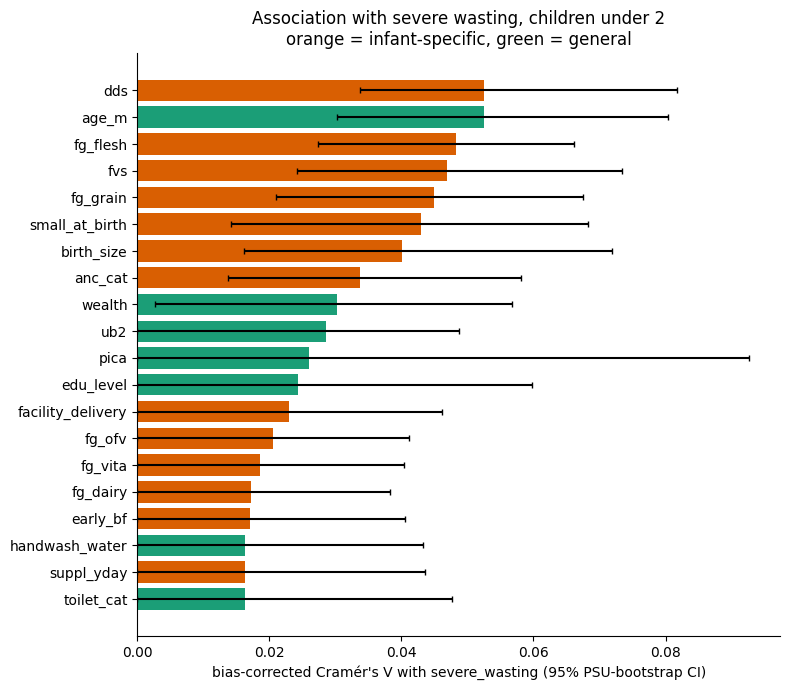

In [6]:
# ===== 6. Association with severe_wasting: V, bootstrap CI, FDR =====
def bh(p):
    p = np.asarray(p, float); n = len(p); o = np.argsort(p); q = p[o] * n / (np.arange(n) + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]; out = np.empty(n); out[o] = np.minimum(q, 1); return out

upsu, pidx = np.unique(PSU, return_inverse=True)
rng = np.random.RandomState(BOOT_SEED)
MULT = np.stack([np.bincount(rng.randint(0, len(upsu), len(upsu)), minlength=len(upsu))[pidx] for _ in range(N_BOOT)]).astype(float)   # N_BOOT x N

out_rows = []
for v in VARS:
    st = v_stats(contingency(CODES[v], Y)); k = min(st['r'] - 1, st['c'] - 1)
    reps = np.array([v_corr_mult(CODES[v], Y, MULT[b]) for b in range(N_BOOT)]); reps = reps[np.isfinite(reps)]
    out_rows.append(dict(variable=v, availability=AVAIL[v], n=int(st['n']), levels=int(st['r']), V=st['V'], V_corr=st['V_corr'], V_corr_ci_lo=np.percentile(reps, 2.5),
                         V_corr_ci_hi=np.percentile(reps, 97.5), V_weighted=v_weighted(CODES[v], Y, W), chi2=st['chi2'], dof=st['dof'], p_unweighted=st['p'],
                         size=size_label(st['V_corr'], k), sparse=bool(st['pct_cells_expected_lt5'] > 20), n_boot_ok=len(reps),
                         case_rate_range_pct='' ))
assoc = pd.DataFrame(out_rows); assoc['fdr_bh'] = bh(assoc['p_unweighted'].values)
# add the range of case rates across levels (descriptive context for V)
for i, v in enumerate(assoc.variable):
    m = CODES[v] >= 0; rates = [100 * Y[m & (CODES[v] == l)].mean() for l in np.unique(CODES[v][m]) if (m & (CODES[v] == l)).sum() >= 30]
    assoc.loc[i, 'case_rate_range_pct'] = f'{min(rates):.1f} to {max(rates):.1f}' if rates else ''
assoc = assoc.sort_values('V_corr', ascending=False).reset_index(drop=True); assoc.to_csv(f'{OUT}/cramers_v_vs_severe_wasting.csv', index=False)
assert (assoc.n_boot_ok >= min(300, N_BOOT)).all() or PROFILE == 'smoke', 'too few successful bootstrap replicates'
with pd.option_context('display.width', 250, 'display.max_rows', 100, 'display.max_colwidth', 28):
    print(f'Association with severe_wasting among {N:,} children under 2 ({Y.sum()} cases); {N_BOOT} PSU-bootstrap replicates')
    print(assoc[['variable', 'availability', 'n', 'levels', 'V_corr', 'V_corr_ci_lo', 'V_corr_ci_hi', 'V', 'V_weighted', 'p_unweighted', 'fdr_bh', 'size', 'case_rate_range_pct']].round(3).to_string(index=False))

top = assoc.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 7))
colors = ['#d95f02' if a == 'infant-specific' else '#1b9e77' for a in top.availability]
ax.barh(top.variable, top.V_corr, color=colors, xerr=[top.V_corr - top.V_corr_ci_lo, top.V_corr_ci_hi - top.V_corr], ecolor='k', capsize=2)
ax.set_xlabel("bias-corrected Cramér's V with severe_wasting (95% PSU-bootstrap CI)"); ax.set_title('Association with severe wasting, children under 2\norange = infant-specific, green = general')
plt.tight_layout(); plt.savefig(f'{FIG}/cramers_v_vs_severe_wasting.png', dpi=130); plt.show()

## 7. Heatmaps and the strongest pairs

* **Full heatmap:** bias-corrected V for all included variables, ordered by hierarchical clustering (so variables that move together sit next to each other).
* **Focus heatmap:** the **infant-specific block** (variables that exist only for infants: diet, breastfeeding, antenatal care and the birth variables) together with `severe_wasting`, age and sex, with the values written in.
* **Strongest pairs:** structural pairs are shown separately from genuine associations.

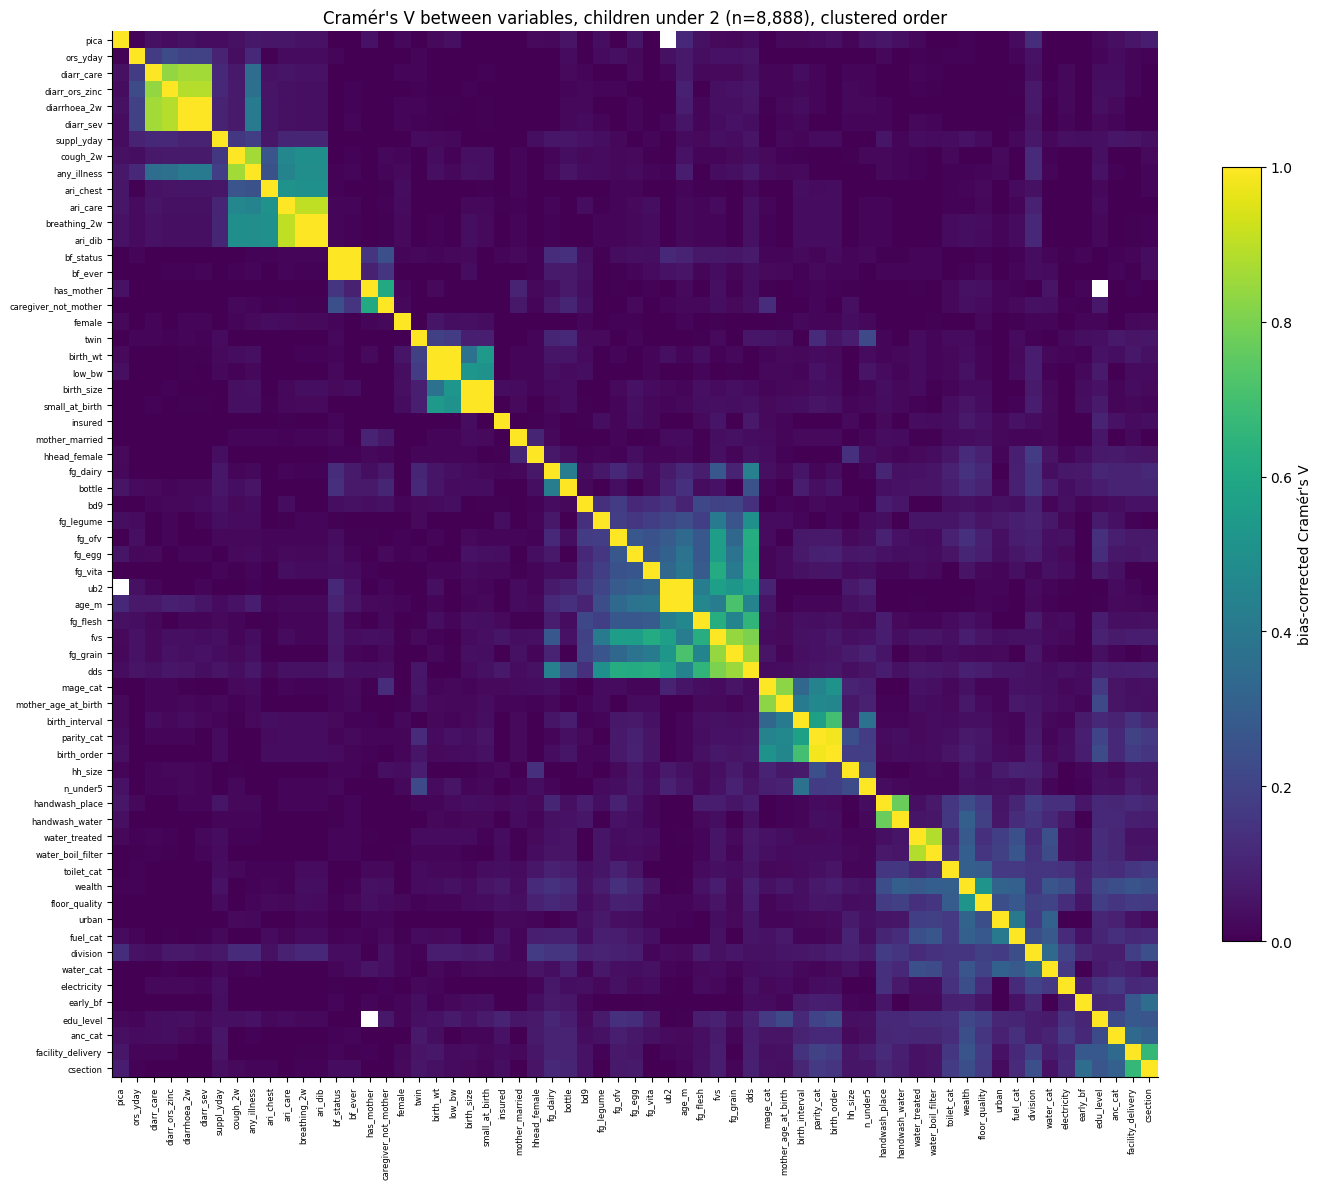

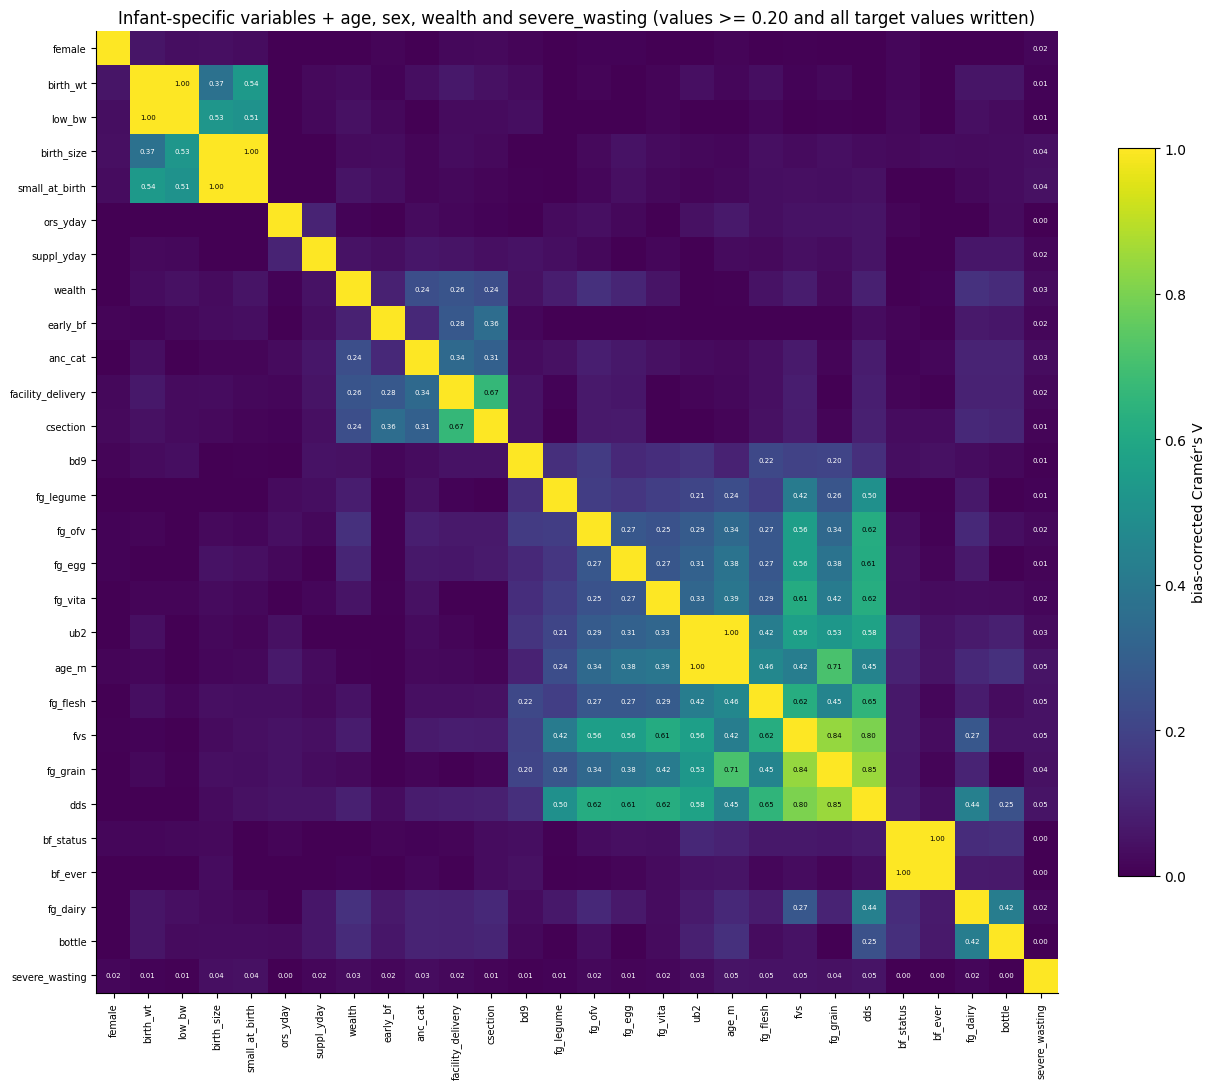

Strongest NON-structural pairs (reliable tables only):
             var1                var2      n  V_corr     V  V_weighted   size flags
            age_m            fg_grain 8882.0   0.714 0.714       0.719  large      
facility_delivery            csection 8611.0   0.666 0.666       0.661  large      
              ub2                 dds 8815.0   0.577 0.577       0.571  large      
              ub2                 fvs 8799.0   0.563 0.564       0.554  large      
              ub2            fg_grain 8882.0   0.530 0.530       0.527  large      
           wealth       floor_quality 8860.0   0.519 0.519       0.525  large      
         mage_cat         birth_order 8822.0   0.508 0.509       0.504  large      
       parity_cat mother_age_at_birth 8822.0   0.467 0.467       0.461  large      
            age_m            fg_flesh 8874.0   0.461 0.462       0.466 medium      
      birth_order mother_age_at_birth 8822.0   0.460 0.460       0.453  large      
         mage_cat    

In [7]:
# ===== 7. Heatmaps and top pairs =====
D = 1 - M_corr.fillna(0).values; np.fill_diagonal(D, 0); order = leaves_list(linkage(squareform(D, checks=False), 'average'))
ordered = [VARS[i] for i in order]
fig, ax = plt.subplots(figsize=(14, 12)); im = ax.imshow(M_corr.loc[ordered, ordered].values, cmap='viridis', vmin=0, vmax=1)
ax.set_xticks(range(len(ordered))); ax.set_xticklabels(ordered, rotation=90, fontsize=6); ax.set_yticks(range(len(ordered))); ax.set_yticklabels(ordered, fontsize=6)
plt.colorbar(im, fraction=0.03, label="bias-corrected Cramér's V"); ax.set_title(f"Cramér's V between variables, children under 2 (n={N:,}), clustered order")
plt.tight_layout(); plt.savefig(f'{FIG}/cramers_v_heatmap_full.png', dpi=130); plt.show()

focus = [v for v in VARS if AVAIL[v] == 'infant-specific'] + [c for c in ['ub2', 'age_m', 'female', 'wealth'] if c in VARS]
focus = list(dict.fromkeys(focus))
# add the target as a row/column of the focus matrix
Mf = pd.DataFrame(np.eye(len(focus) + 1), index=focus + [TARGET], columns=focus + [TARGET])
for a in focus:
    for b in focus:
        if a != b: Mf.loc[a, b] = M_corr.loc[a, b]
    Mf.loc[a, TARGET] = Mf.loc[TARGET, a] = assoc.set_index('variable').loc[a, 'V_corr']
Mf.round(4).to_csv(f'{OUT}/cramers_v_matrix_infant_focus.csv')
fo = [focus[i] for i in leaves_list(linkage(squareform(np.nan_to_num(1 - Mf.loc[focus, focus].values, nan=1) * (1 - np.eye(len(focus))), checks=False), 'average'))] + [TARGET]
fig, ax = plt.subplots(figsize=(13, 11)); vals = Mf.loc[fo, fo].values
im = ax.imshow(vals, cmap='viridis', vmin=0, vmax=1)
for i in range(len(fo)):
    for j in range(len(fo)):
        if np.isfinite(vals[i, j]) and i != j and (vals[i, j] >= 0.2 or fo[i] == TARGET or fo[j] == TARGET): ax.text(j, i, f'{vals[i, j]:.2f}', ha='center', va='center', fontsize=5, color='w' if vals[i, j] < 0.6 else 'k')
ax.set_xticks(range(len(fo))); ax.set_xticklabels(fo, rotation=90, fontsize=7); ax.set_yticks(range(len(fo))); ax.set_yticklabels(fo, fontsize=7)
plt.colorbar(im, fraction=0.03, label="bias-corrected Cramér's V"); ax.set_title("Infant-specific variables + age, sex, wealth and severe_wasting (values >= 0.20 and all target values written)")
plt.tight_layout(); plt.savefig(f'{FIG}/cramers_v_heatmap_infant_focus.png', dpi=130); plt.show()

good = pairs[~pairs['flags'].str.contains('small_n|sparse')]
genuine = good[~good['flags'].str.contains('structural|near_duplicate')].sort_values('V_corr', ascending=False)
struct = good[good['flags'].str.contains('structural|near_duplicate')].sort_values('V_corr', ascending=False)
genuine.head(40).to_csv(f'{OUT}/top_pairs_genuine.csv', index=False); struct.to_csv(f'{OUT}/top_pairs_structural.csv', index=False)
cols = ['var1', 'var2', 'n', 'V_corr', 'V', 'V_weighted', 'size', 'flags']
with pd.option_context('display.width', 230):
    print('Strongest NON-structural pairs (reliable tables only):'); print(genuine.head(25)[cols].round(3).to_string(index=False))
    print('\nStrongest structural / near-duplicate pairs (high V by construction; do not enter the same model blindly):'); print(struct.head(15)[cols].round(3).to_string(index=False))
    print('\nPairs involving infant-specific variables, strongest reliable ones:')
    inf = genuine[(genuine.avail1 == 'infant-specific') | (genuine.avail2 == 'infant-specific')]; print(inf.head(15)[cols].round(3).to_string(index=False))

## 8. Findings, files and limitations

The next cell builds the summary from the saved tables, so it cannot disagree with the numbers above.

In [8]:
# ===== 8. Auto-generated findings and manifest =====
sig = assoc[(assoc.fdr_bh < 0.05)]; ci_pos = assoc[assoc.V_corr_ci_lo > 0]
print('=' * 90); print(f"CRAMER'S V FINDINGS: {N:,} children under 2, {int(Y.sum())} severe cases, {len(VARS)} variables, {len(pairs):,} pairs, profile={PROFILE}"); print('=' * 90)
print(f'\nAssociation with severe_wasting: {len(sig)} variable(s) with FDR < 0.05 (unweighted chi-square screening); {len(ci_pos)} with a PSU-bootstrap interval above zero.')
for r_ in assoc.head(8).itertuples():
    print(f'  {r_.variable:20s} V_corr={r_.V_corr:.3f} (95% CI {r_.V_corr_ci_lo:.3f}-{r_.V_corr_ci_hi:.3f}), FDR={r_.fdr_bh:.3f}, {r_.size}, case rates by level (% , levels with n>=30): {r_.case_rate_range_pct}')
print(f'\nLargest V with the outcome overall is {assoc.V_corr.max():.3f}: with about {Y.mean()*100:.1f}% prevalence, V stays small for every variable; judge by interval and ranking, not by size alone.')
inf_assoc = assoc[assoc.availability == 'infant-specific']
print(f'Infant-specific variables: {len(inf_assoc)} tested; strongest: ' + ', '.join(f'{r.variable} ({r.V_corr:.3f})' for r in inf_assoc.head(4).itertuples()))
print(f'\nBetween predictors: {int((genuine.V_corr >= 0.3).sum())} non-structural reliable pairs have V_corr >= 0.30 and {int((genuine.V_corr >= 0.5).sum())} have >= 0.50; ' 
      f'{len(struct)} structural/near-duplicate pairs are highest. Strongest genuine pair: {genuine.iloc[0].var1} x {genuine.iloc[0].var2} (V_corr={genuine.iloc[0].V_corr:.3f}).')
print(f'Unreliable tables: {int(pairs['flags'].str.contains("sparse").sum())} sparse and {int(pairs['flags'].str.contains("small_n").sum())} small-n pairs (excluded from the top-pair lists).')

def sha256(p):
    h = hashlib.sha256()
    with open(p, 'rb') as fh:
        for ch in iter(lambda: fh.read(1 << 20), b''): h.update(ch)
    return h.hexdigest()
manifest = {'profile': PROFILE, 'n_boot': N_BOOT, 'children_under2': int(N), 'cases': int(Y.sum()), 'variables_included': VARS, 'n_pairs': int(len(pairs)),
            'data_file': os.path.basename(path), 'data_sha256': sha256(path), 'python': platform.python_version(),
            'versions': {m: getattr(sys.modules.get(m), '__version__', None) for m in ['numpy', 'pandas', 'scipy', 'matplotlib']},
            'runtime_minutes': round((time.time() - T0) / 60, 2), 'outputs': sorted(os.listdir(OUT)), 'figures': sorted(os.listdir(FIG))}
json.dump(manifest, open(f'{OUT}/run_manifest.json', 'w'), indent=2, default=str)
print(f'\nSaved {len(manifest["outputs"])} files in {OUT}/ and {len(manifest["figures"])} figures in {FIG}/ ({manifest["runtime_minutes"]} min).')

CRAMER'S V FINDINGS: 8,888 children under 2, 297 severe cases, 63 variables, 1,953 pairs, profile=standard

Association with severe_wasting: 9 variable(s) with FDR < 0.05 (unweighted chi-square screening); 9 with a PSU-bootstrap interval above zero.
  dds                  V_corr=0.053 (95% CI 0.034-0.082), FDR=0.001, negligible, case rates by level (% , levels with n>=30): 1.4 to 4.9
  age_m                V_corr=0.052 (95% CI 0.030-0.080), FDR=0.000, negligible, case rates by level (% , levels with n>=30): 2.4 to 5.1
  fg_flesh             V_corr=0.048 (95% CI 0.027-0.066), FDR=0.000, negligible, case rates by level (% , levels with n>=30): 2.1 to 4.0
  fvs                  V_corr=0.047 (95% CI 0.024-0.073), FDR=0.001, negligible, case rates by level (% , levels with n>=30): 2.5 to 4.6
  fg_grain             V_corr=0.045 (95% CI 0.021-0.067), FDR=0.000, negligible, case rates by level (% , levels with n>=30): 2.7 to 4.5
  small_at_birth       V_corr=0.043 (95% CI 0.014-0.068), FDR=0.0

### Limitations (read before using any number above)

* **V measures strength, not direction or cause.** It does not say whether a level raises or lowers risk (the case-rate ranges beside each variable give a rough idea) and it says nothing about causation.
* **Not design-based.** The chi-square tests ignore weights and PSU clustering and are used only for screening; the bootstrap intervals respect clustering but do not use the survey weights in the statistic. Weighted V is descriptive.
* **Pairwise-complete cases.** Each pair uses the children who have both values, so pair sample sizes differ (see `cramers_v_pair_sample_sizes.csv`); variables with partial coverage (for example `birth_wt` and `pica`) are based on fewer children.
* **Recoding choices matter.** Binning of continuous variables and merging of rare ordered levels change V; the rules are printed in the inventory and can be edited in section 3.
* **Structural pairs and sparse tables** are flagged but still reported in the full files; high V between derived variables is expected, not informative.
* **Variable derivations are unverified** because no codebook was available.
* **Pairwise V does not capture joint structure**: two variables can each look unrelated to the outcome and still be informative together, or look related only because both depend on age or wealth.